In [390]:
import numpy as np 
import math
from scipy.special import jv
import matplotlib.pyplot as plt

In [391]:
#f1 = 50 
f2 = 20000

#w1 = 2*math.pi*f1
w2 = 2*math.pi*f2

dp_hf = 0.2e-3#0.3866424e-3
n_litz = 120
dp_hf_outer = 3.001
thick_s_hf = 56/45.8
print(thick_s_hf)

con_copper =  59.6e6 #conductivity of copper
my_0 = 4*math.pi*1e-7


#skin_depth_1 = np.sqrt(2/(w1*1*my_0*con_copper))
skin_depth_2 = np.sqrt(2/(w2*1*my_0*con_copper))
print( skin_depth_2)

v = (thick_s_hf * 1e-3)/skin_depth_2
xip_hf = dp_hf/(np.sqrt(2)*skin_depth_2)

# Calculate required current
I = (0.3 * 24e-3) / (my_0 * 2000 * 1)

print("Required current:", I, "A")

1.2227074235807862
0.0004609799154750085
Required current: 2.864788975654116 A


Calculate Area of Acp

In [392]:
k_p = 0.3 #filling factor Litz wire
A_cp = 277.09/(16*16*k_p+1)
A_cs= 16*A_cp
print(A_cp, A_cs)

3.561568123393316 56.985089974293054


In [393]:
def calc_N_windings(Voltage, B, w, A_core):
    """
    Number of Windings

    Parameters
    ----------
    Voltage : float or ndarray
        voltage of the coil

    B :  float or ndarray
        selected magnetic flux density in T

    w : float or ndarray
        omega, 2*pi*frequency

    A_core: float or ndarray
        cross-sectional area of the core

    Returns
    -------
    N_w: number of Windings with these parameters
    """
    N_w = Voltage/(w*B*A_core)
    return N_w



In [394]:
"""High-frequency B_VALUE JUST SELECTED WITH 30s OF RESEARCH, INVESTIGATE FURTHER (in this case i selected the higest line of the N27 Core loss graphic)"""
N_p_hf = calc_N_windings(230*np.sqrt(2), 0.3, w2, 20e-3*27.4e-3)     #number of primary side windings lf-Transformer
N_s_hf = calc_N_windings( 15*np.sqrt(2), 0.3, w2, 20e-3*27.4e-3)     #number of secondary side windings lf-Transformer

print(N_p_hf, N_s_hf)

15.744582779511438 1.026820616055094


In [395]:
"""HF TRANSFORMER MATRIX CALCULATIONS"""

# Known values
V1 = 230 + 0j
I1 = 16.4706 + 0j

# Complex impedances
L1 = 1j * w2 * 2.8697712e-3
L2 = 1j * w2 * 9.9326835e-6
M  = 1j * w2 * 168.7e-6

print(L1, L2, M)

# Solve for unknown I2
I2 = (V1 - L1 * I1) / M
print((M * I1) , (L2 * I2))

# Calculate unknown V2
V2 = (M * I1) + (L2 * I2)

# Results
print(f"I2 = {I2:.6f} A")
print(f"V2 = {V2:.6f} V")

print(f"|I2| = {np.abs(I2):.6f} A")
print(f"|V2| = {np.abs(V2):.6f} V")

print(f"I2 phase = {np.angle(I2, deg=True):.2f}°")
print(f"V2 phase = {np.angle(V2, deg=True):.2f}°")

print("P1 = ", np.real(V1*I1))
print("P2 = ", np.real(V2*I2))
print("Efficency: ", 100*np.real(V2*I2)/np.real(V1*I1))


360.62608477614265j 1.2481778205613023j 21.199467226423927j
349.16794489953793j (13.541892145820983-349.7180688783147j)
I2 = -280.182890-10.849329j A
V2 = 13.541892-0.550124j V
|I2| = 280.392867 A
|V2| = 13.553062 V
I2 phase = -177.78°
V2 phase = -2.33°
P1 =  3788.2380000000003
P2 =  -3800.1749523551925
Efficency:  -100.31510566007712


# Losses

## skineffect + DC resistance
all kinds of support formulas

In [396]:
def ber(n, xi):
    """Kelvin function ber of order n."""
    z = xi * np.exp(3j * np.pi / 4)
    return np.real(jv(n, z))


def bei(n, xi):
    """Kelvin function bei of order n."""
    z = xi * np.exp(3j * np.pi / 4)
    return np.imag(jv(n, z))


def G_R(xi, d):
    """
    Proximity-effect coefficient for a round conductor.

    Parameters
    ----------
    xi : float or ndarray
        Dimensionless parameter d / (sqrt(2) * delta).
    d : float
        Conductor diameter [m].

    Returns
    -------
    G_R : float or ndarray
        Proximity-effect coefficient [m^2].
    """

    ber0 = ber(0, xi)
    ber1 = ber(1, xi)
    ber2 = ber(2, xi)

    bei0 = bei(0, xi)
    bei1 = bei(1, xi)
    bei2 = bei(2, xi)

    denominator = ber0**2 + bei0**2

    term1 = (ber2 * ber1 + ber2 * bei1) / denominator

    term2 = (bei2 * bei1 - bei2 * ber1) / denominator

    GR = -(xi * np.pi**2 * d**2) / (2 * np.sqrt(2)) * (term1 + term2)

    return GR

def F_R(xi):
    """
    Skin-effect resistance factor for a round conductor.

    Parameters
    ----------
    xi : float or ndarray
        Dimensionless parameter d / (sqrt(2) * delta).

    Returns
    -------
    F_R : float or ndarray
        Skin-effect resistance factor (dimensionless).
    """

    ber0 = ber(0, xi)
    ber1 = ber(1, xi)

    bei0 = bei(0, xi)
    bei1 = bei(1, xi)

    denominator = ber1**2 + bei1**2

    term1 = (ber0 * bei1 - ber0 * ber1) / denominator

    term2 = (bei0 * ber1 + bei0 * bei1) / denominator

    FR = (xi / (4 * np.sqrt(2))) * (term1 - term2)

    return FR


def F_F(nu):
    """
    Skin-effect resistance factor for a foil conductor.

    Parameters
    ----------
    nu : float or ndarray
        Dimensionless parameter.

    Returns
    -------
    F_F : float or ndarray
        Skin-effect resistance factor (dimensionless).
    """

    numerator = nu * (np.sinh(nu) + np.sin(nu))

    denominator = 4 * (np.cosh(nu) - np.cos(nu))

    FF = numerator / denominator

    return FF


def G_F(nu, b):
    """
    Proximity-effect coefficient for a foil conductor.

    Parameters
    ----------
    nu : float or ndarray
        Dimensionless parameter.
    b : float
        Foil conductor width [m].

    Returns
    -------
    G_F : float or ndarray
        Proximity-effect coefficient [m^2].
    """

    numerator = b**2 * nu * (np.sinh(nu) - np.sin(nu))

    denominator = np.cosh(nu) + np.cos(nu)

    GF = numerator / denominator

    return GF





def calculate_L(x):
    #calculate length of one turn in mm
    L = 2*(20+27.4)+8*(x-10)
    return L


def calculate_L_coil(x,N):
    #calculate length of whole wire in m
    L = calculate_L(x)*N/1000
    return L

Formulas for DC and Skin resistance

In [397]:
def r_dc(d_i, sigma=con_copper):
    """
    DC resistance per unit length of one strand [Ohm/m].
    """
    return 4/(sigma * np.pi * d_i * d_i)

def r_dc_foil(b, h, sigma=con_copper):
    """
    b = how wide 
    h = how thick 
    """

    return 1/(sigma*b*h)


def P_dc_skin(xi, d_i, n_str, I_hat, L_coil):
    """
    DC + skin-effect losses of Litz wire [W].

    xi     : Dimensionless parameter
    d_i    : Individual strand diameter [m]
    n_str  : Number of strands
    I_hat  : Peak current through the complete Litz wire [A]
    L_coil : Total conductor length [m]
    """

    R = r_dc(d_i)

    P = n_str * R * F_R(xi) * (I_hat / n_str)**2 * L_coil

    return P

def P_dc_skin_foil(v,R_DC_foil, I_max, Length):
    """
    F_F = F_F value
    others trivial
    """
    return F_F(v)*R_DC_foil*I_max**2*Length


In [398]:
P_skindc_p_hf = np.real(P_dc_skin(xip_hf, dp_hf, n_litz, I1*np.sqrt(2),calculate_L_coil(17.322,17)))
P_skindc_s_hf = P_skindc_s_hf = np.real(P_dc_skin_foil(
    v,
    r_dc_foil(45.8e-3, thick_s_hf*1e-3),
    I2*np.sqrt(2),
    calculate_L_coil(10+thick_s_hf/2, 1)
))
print("Powerloss primary: ",P_skindc_p_hf)
print("Powerloss secondary: ",P_skindc_s_hf)
"""
print("diameter: ", dp_lf)
print("Xi: ",xip_lf)
print("L_coil: ", calculate_L_coil(22.1,N_p_lf))
print("I: ", I1*np.sqrt(2))
print("R_dc:", r_dc(dp_lf, sigma=con_copper)*calculate_L_coil(22.1,N_p_lf))

print(5*math.pi*(dp_lf*1000/2)**2)
"""
print(I2)

Powerloss primary:  3.1482399491857023
Powerloss secondary:  2.91771348507808
(-280.18288990349737-10.849329256412544j)


Formula for internal proximity:

In [399]:
def P_internal_proximity(xi, d_i, d_a, n_str, I_hat, L_coil):
    """
    Internal proximity-effect losses of Litz wire [W].

    xi     : Dimensionless parameter
    d_i    : Individual strand diameter [m]
    d_a    : Outer diameter of complete Litz wire [m]
    n_str  : Number of strands
    I_hat  : Peak current through the complete Litz wire [A]
    L_coil : Total conductor length [m]
    """

    R = r_dc(d_i)

    P = (n_str * R * G_R(xi, d_i)
         * I_hat**2 / (2 * np.pi**2 * d_a**2)
         * L_coil)

    return P

In [400]:
# Calculate internal proximity losses
P_prox_p_hf = P_internal_proximity(xip_hf, dp_hf,dp_hf_outer,n_litz,np.abs(I1)*np.sqrt(2), calculate_L_coil(24.644,17))
#P_prox_s_lf = P_internal_proximity(xip_lf, ds_lf, ds_lf, 1, np.abs(I2)*np.sqrt(2), calculate_L_coil(22.1,N_s_lf))

print("Internal Proximity Primary: ",P_prox_p_hf)
#print("Internal Proximity Secondary: ",P_prox_s_lf)

Internal Proximity Primary:  7.699990833725997e-08


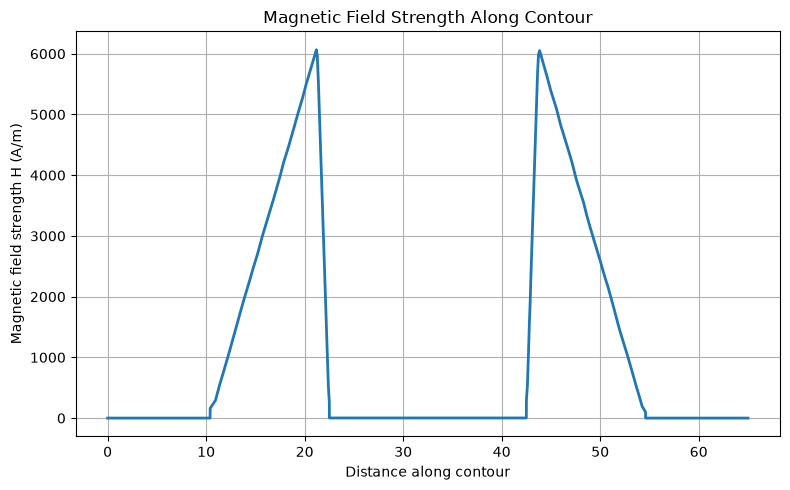

In [401]:
# Load FEMM exported data
data = np.loadtxt("H_contour_HF.txt", skiprows=1, delimiter=",")

# Extract columns
l_hf = data[:, 0]  # Distance along contour
H_hf = data[:, 1]  # Magnetic field strength (A/m)

# Plot magnetic field strength
plt.figure(figsize=(8, 5))

plt.plot(l_hf, H_hf, linewidth=2)

plt.xlabel("Distance along contour")
plt.ylabel("Magnetic field strength H (A/m)")
plt.title("Magnetic Field Strength Along Contour")

plt.grid(True)
plt.tight_layout()
plt.show()

In [402]:
def ext_prox_hf(H_femm, xi_p, xi_s, d_p_lf, d_s_lf, n_str, N_prim, N_sec):
    """
    Calculates the proximity effect in one section of wires on the y-Axis

    Parameters
    ----------
    xi :  Dimensionless skin-depth parameter.

    d_i : Copper strand diameter [m].

    x :   the x-value of the layer (zero is in the middle of the transformer)

    H :   Magnetic field strength array from femm [A/m].

    k_f: packing factor

    N: Number of turns

    Returns
    -------
    P_ex : External proximity-effect losses [W].
    """
    """
    x_femm, H_femm = transform_H_to_to_new_zero(x_femm,H_femm)
    k_f_one_dim = np.sqrt(k_f)
    number_wires = 22.9*2/(d_i*k_f_one_dim)
    Area_one_wire = (d_i/2)**2*3.14
    """


    H_max = np.max(H_femm)
    H_working = H_max/2
    """averange Length of the sectors"""
    #sector 1: (secondary, right side)
    x1 = 10.636   #How long overall secondary, half on the left, middle for the average
    L1 = calculate_L(x1)*1e-3
    #sector 2: (primary)
    x2 = 17.322
    L2 = calculate_L(x2)*1e-3

    lineintegral1 = L1*(H_max/2)**2*N_sec
    lineintegral2 = L2*(H_max/2)**2*N_prim

    sum_lineintrgral_s = lineintegral1
    sum_lineintrgral_p = lineintegral2

    rdc_p = 4/(con_copper*3.14*d_p_lf**2)
    rdc_s = rdc_s = r_dc_foil(45.8e-3, thick_s_hf * 1e-3)

    Gr_p= G_R(xi_p,d_p_lf)
    Gr_s = G_F(xi_s, thick_s_hf * 1e-3)
    res_p = n_str*rdc_p*Gr_p*sum_lineintrgral_p
    res_s = 1    *rdc_s*Gr_s*sum_lineintrgral_s
    return res_p, res_s

In [403]:
P_ext_p, P_ext_s = ext_prox_hf(H_hf,xip_hf,v, dp_hf, thick_s_hf,n_litz,17,11)
print(P_ext_p, P_ext_s)

0.16802229075159006 0.012666371590544182


# Core losses LF
Volume of Core pair according to TDK Datasheet: 78650 mm^3

In [404]:
Volume        = 78650 #mm^3
dens_lf       = 7.65  #kg/dm^3
P_core_rel_lf = 0.633 #W/kg from datasheet

weight_lf_core = Volume * dens_lf / 1000000
P_core_lf = weight_lf_core*P_core_rel_lf
print(weight_lf_core)
print(P_core_lf)

0.6016725
0.38085869250000004


# Efficency LF

In [405]:
P_input_lf = np.real(V1*np.conj(I1))
P_losses_lf = P_skindc_p_hf + P_skindc_s_hf + P_prox_p_hf + P_ext_p + P_ext_s + P_core_lf

print("Losses: ", P_losses_lf)

efficency_lf = (P_input_lf-P_losses_lf)/P_input_lf
print(efficency_lf)

Losses:  6.627500866105827
0.9982505056793934
